# Adversarial decoys against attention-based defenses: single-image demo

This notebook runs the full pipeline with a ViT-S/16 on one image from the ImageNet validation subset evaluated in the paper:

1. **Patch-Fool** replaces a few image tokens with an adversarial patch that both fools the classifier and attracts attention.
2. **ARMRO**, an attention-based defense, spots those abnormally attended tokens, masks them and restores the prediction.
3. An **adversarial decoy** is added on *other* tokens. It is optimized only to become the most attended region, so ARMRO masks the decoy instead of the attack, and the adversarial prediction survives the defense.

Iteration counts are reduced so that the notebook runs in a few minutes on CPU. Set `PAPER_SETTINGS = True` to use the values of the paper.

## a. Setup

Device selection, fixed seed, and the pretrained `vit_small_patch16_224` from timm (weights are downloaded on first use). All hyperparameters are in the cell below; the defaults follow the ViT-S runs of the paper except for the number of iterations.

In [1]:
import os
import sys
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from timm.data import ImageNetInfo

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from advdecoy.models.vit import load_timm_vit, get_timm_data_config, normalize_img, vit_forward_with_attention, predict_with_attention
from advdecoy.attacks.patch_fool import select_tokens_by_attention, optimize_patch_fool
from advdecoy.attacks.decoy import sample_decoy_tokens, optimize_attention_decoy
from advdecoy.defenses.armro import evaluate_armro_defense
from advdecoy.utils.patches import tokens_to_mask
from advdecoy.utils.attention import received_attention_map, cls_attention_map
from advdecoy.utils.viz import show_image, show_attention, draw_tokens, show_topk, topk

In [2]:
PAPER_SETTINGS = False  # True: iteration counts used in the paper (slower)

# Image from the ImageNet validation subset evaluated in the paper (seed 5).
IMAGE_PATH = os.path.join(ROOT, "assets", "ILSVRC2012_val_00029267.JPEG")
LABEL = 292                 # ImageNet ground truth; None uses the clean prediction (e.g. for assets/coffee.png)
MODEL_NAME = "vit_small_patch16_224"
SEED = 5

# Patch-Fool
PF_NUM_TOKENS = 2           # attacked tokens (the paper reports 1, 2 and 4)
PF_SELECT_LAYER = 4         # layer used to pick the most attended tokens
PF_STEPS = 500 if PAPER_SETTINGS else 250
PF_LR = 5e-2
PF_ATTENTION_WEIGHT = 0.02
PF_EOT_MASK_RATIO = 0.0     # 0.05 gives the Patch-Fool EOT variant of the paper

# Decoy
DECOY_NUM_TOKENS = 4
DECOY_STEPS = 2500 if PAPER_SETTINGS else 500
DECOY_LR = 5e-2
DECOY_BETA_RATIO = 2.0

# ARMRO (tau = 1.4 for ViT-S, 1.2 for ViT-B / DeiT-B in the paper)
ARMRO_ND = 5
ARMRO_TAU = 1.4

LAYERS = list(range(12))    # layers used by both the decoy loss and ARMRO
IMAGE_SIZE, PATCH_SIZE = 224, 16
GRID_SIZE = IMAGE_SIZE // PATCH_SIZE

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
t_start = time.time()

model = load_timm_vit(MODEL_NAME, DEVICE)
data_config = get_timm_data_config(model)
mean, std = data_config["mean"], data_config["std"]

normalize_fn = lambda x: normalize_img(x, mean, std)
predict_fn = lambda m, x: predict_with_attention(m, x, mean, std)

imagenet_info = ImageNetInfo()
class_names = [imagenet_info.index_to_description(i).split(",")[0] for i in range(1000)]
name = lambda c: f"{class_names[c]} ({c})"

print(f"device: {DEVICE} | model: {MODEL_NAME} | paper settings: {PAPER_SETTINGS}")

device: cuda | model: vit_small_patch16_224 | paper settings: False


## b. Clean image

The image is resized to 224×224, as in the paper, and classified; the attack targets its ground-truth label. The middle panel shows the CLS-to-patch attention; the right panel shows the attention *received* by each token from all queries, which is the statistic ARMRO inspects.

label: tiger (292) | clean prediction correct: True

0.929  tiger (292)
0.053  tiger cat (282)
0.003  jaguar (290)
0.003  patas (371)
0.001  dhole (274)


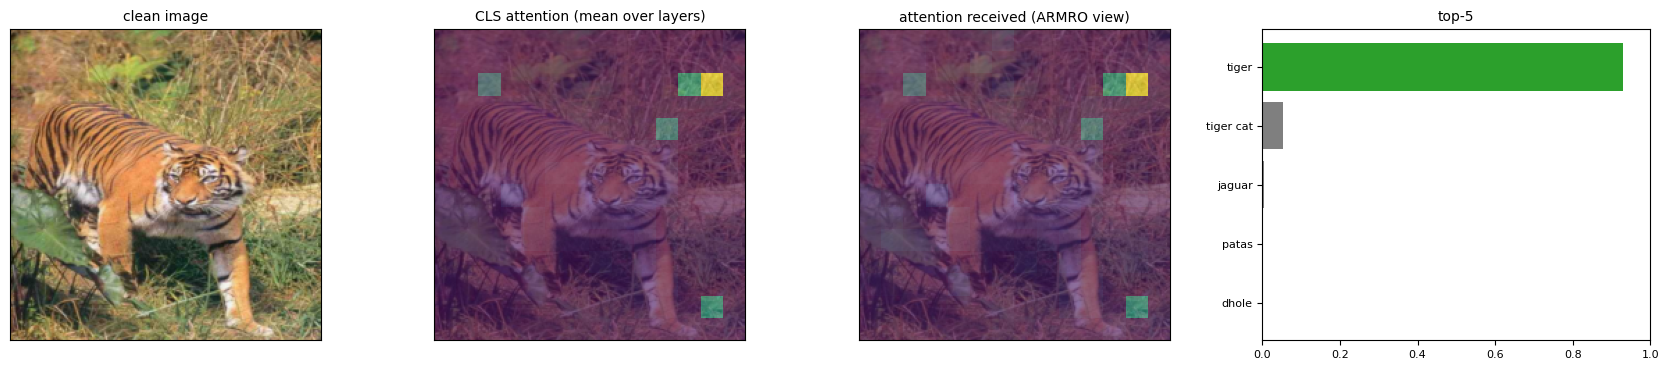

In [3]:
x_clean = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()])(
    Image.open(IMAGE_PATH).convert("RGB")
).unsqueeze(0).to(DEVICE)

clean_out = predict_fn(model, x_clean)
label = LABEL if LABEL is not None else int(clean_out["pred"])
print(f"label: {name(label)} | clean prediction correct: {int(clean_out['pred']) == label}\n")

for c, p in topk(clean_out["probs"]):
    print(f"{p:.3f}  {name(c)}")

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
show_image(axes[0], x_clean, "clean image")
show_attention(axes[1], x_clean, cls_attention_map(clean_out["attn_maps"]), "CLS attention (mean over layers)")
show_attention(axes[2], x_clean, received_attention_map(clean_out["attn_maps"], LAYERS), "attention received (ARMRO view)")
show_topk(axes[3], clean_out["probs"], class_names, highlight=label, title="top-5")
plt.tight_layout()
plt.show()

## c. Patch-Fool attack

Patch-Fool picks the tokens that receive most attention at layer 4 and replaces them with a free patch. The patch is optimized to maximize the cross-entropy of the true label plus an attention term that pulls attention towards the attacked tokens (the two gradients are reconciled with PCGrad). The result is a misclassified image where the attacked tokens (green) dominate the attention.

attacked tokens: [101, 135]
[Patch-Fool] step    1/250 | ce=0.0681 | pred=292
[Patch-Fool] step   51/250 | ce=2.2336 | pred=282
[Patch-Fool] step  101/250 | ce=4.3272 | pred=464
[Patch-Fool] step  151/250 | ce=5.1150 | pred=638
[Patch-Fool] step  201/250 | ce=5.5257 | pred=678
[Patch-Fool] step  250/250 | ce=5.8538 | pred=459

clean: tiger (292) -> attacked: brassiere (459) | attack success: True


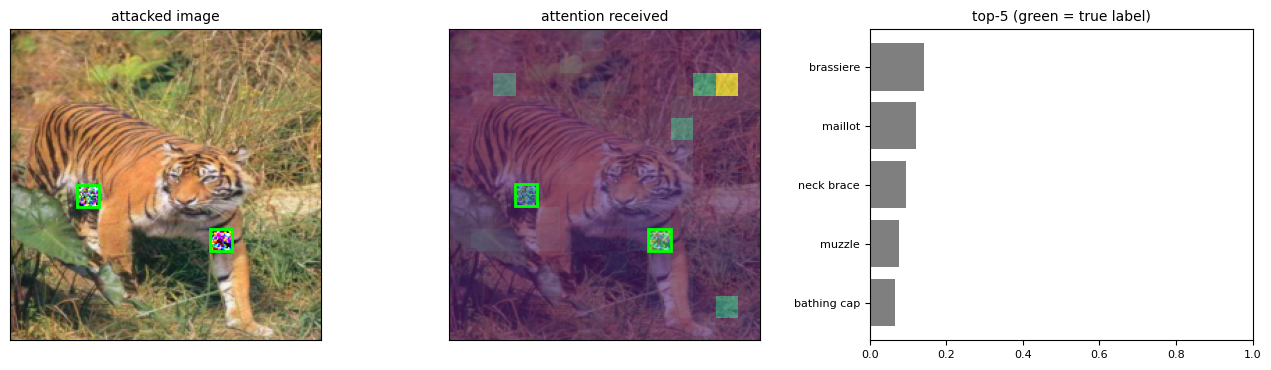

In [4]:
attack_tokens = select_tokens_by_attention(clean_out["attn_maps"], PF_NUM_TOKENS, select_layer=PF_SELECT_LAYER)
print("attacked tokens:", attack_tokens)

pf_result = optimize_patch_fool(
    model, x_clean, label, normalize_fn, vit_forward_with_attention, attack_tokens,
    steps=PF_STEPS, lr=PF_LR, patch_size=PATCH_SIZE, attention_weight=PF_ATTENTION_WEIGHT,
    eot_mask_ratio=PF_EOT_MASK_RATIO,
)
x_adv = pf_result["x_adv_01"]
adv_out = predict_fn(model, x_adv)
adv_pred = int(adv_out["pred"])

print(f"\nclean: {name(label)} -> attacked: {name(adv_pred)} | attack success: {adv_pred != label}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
show_image(axes[0], x_adv, "attacked image")
draw_tokens(axes[0], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
show_attention(axes[1], x_adv, received_attention_map(adv_out["attn_maps"], LAYERS), "attention received")
draw_tokens(axes[1], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
show_topk(axes[2], adv_out["probs"], class_names, highlight=label, title="top-5 (green = true label)")
plt.tight_layout()
plt.show()

## d. ARMRO on the attacked image

ARMRO looks, layer by layer, at the 5 most attended tokens and flags a token when its score is more than τ times the next one. The flagged tokens (magenta, dashed) are replaced by the mean image color and the image is classified again. Because Patch-Fool concentrates attention on the attacked tokens, ARMRO finds them and restores the correct prediction.

ARMRO masks: [40, 101, 135] | attacked tokens masked: [101, 135]
prediction after ARMRO: tiger (292) | true label restored: True


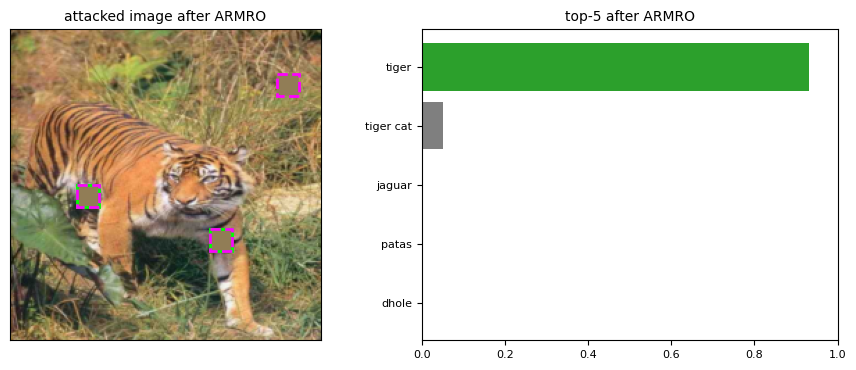

In [5]:
def_adv = evaluate_armro_defense(model, x_adv, adv_out["attn_maps"], predict_fn, LAYERS, n_d=ARMRO_ND, tau=ARMRO_TAU, patch_size=PATCH_SIZE)
def_adv_pred = int(def_adv["after"]["pred"])
masked_adv = def_adv["selected_tokens"][0]

print("ARMRO masks:", masked_adv, "| attacked tokens masked:", sorted(set(masked_adv) & set(attack_tokens)))
print(f"prediction after ARMRO: {name(def_adv_pred)} | true label restored: {def_adv_pred == label}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
show_image(axes[0], def_adv["x_defended_01"], "attacked image after ARMRO")
draw_tokens(axes[0], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
draw_tokens(axes[0], masked_adv, GRID_SIZE, PATCH_SIZE, color="magenta", linestyle="--")
show_topk(axes[1], def_adv["after"]["probs"], class_names, highlight=label, title="top-5 after ARMRO")
plt.tight_layout()
plt.show()

## e. Optimizing the decoy

The decoy is placed on randomly chosen tokens (fixed seed) that do not overlap with the attack, and initialized to gray. Its pixels are optimized only on an attention loss that makes the decoy tokens the most attended tokens in every layer, by maximizing the ratio between the weakest top-3 decoy score and the strongest non-decoy score. The classifier output is not used. The attention maps before and after the optimization show the attention moving from the attacked tokens (green) to the decoy (cyan).

decoy tokens: [59, 151, 179, 158]
[decoy] step    1/500 | loss=124.6585 | layers with decoy/other ratio > 1: 0/12 | pred=459
[decoy] step  101/500 | loss=57.3747 | layers with decoy/other ratio > 1: 5/12 | pred=292
[decoy] step  201/500 | loss=51.2076 | layers with decoy/other ratio > 1: 5/12 | pred=292
[decoy] step  301/500 | loss=43.7618 | layers with decoy/other ratio > 1: 8/12 | pred=292
[decoy] step  401/500 | loss=41.8745 | layers with decoy/other ratio > 1: 8/12 | pred=292
[decoy] step  500/500 | loss=38.0239 | layers with decoy/other ratio > 1: 10/12 | pred=292

prediction with attack + decoy (no defense): tiger (292)


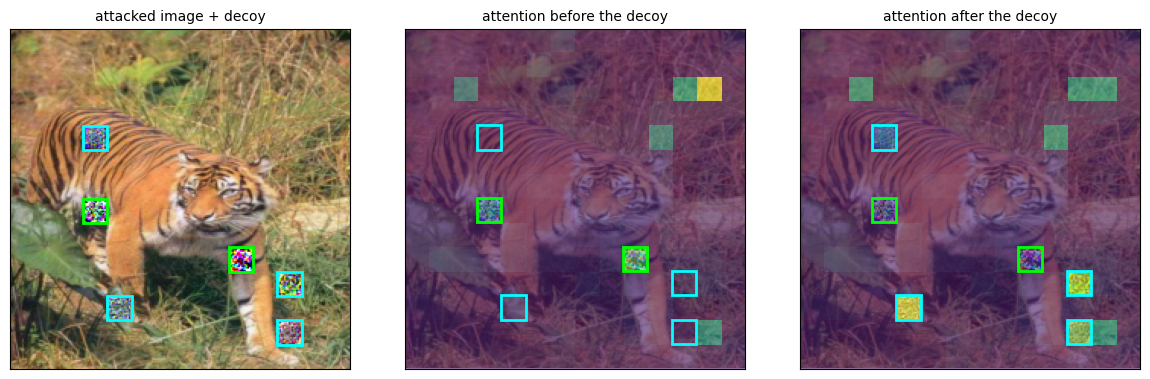

In [6]:
generator = torch.Generator()
generator.manual_seed(SEED)
decoy_tokens = sample_decoy_tokens(GRID_SIZE, DECOY_NUM_TOKENS, attack_tokens, generator=generator)
print("decoy tokens:", decoy_tokens)

decoy_result = optimize_attention_decoy(
    model, x_adv, normalize_fn, vit_forward_with_attention,
    tokens_to_mask(decoy_tokens, IMAGE_SIZE, PATCH_SIZE, device=DEVICE),
    LAYERS, decoy_tokens, GRID_SIZE,
    steps=DECOY_STEPS, lr=DECOY_LR, beta_ratio=DECOY_BETA_RATIO,
)
x_decoy = decoy_result["x_final_01"]
decoy_out = predict_fn(model, x_decoy)
decoy_pred = int(decoy_out["pred"])
print(f"\nprediction with attack + decoy (no defense): {name(decoy_pred)}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
show_image(axes[0], x_decoy, "attacked image + decoy")
draw_tokens(axes[0], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
draw_tokens(axes[0], decoy_tokens, GRID_SIZE, PATCH_SIZE, color="cyan")
show_attention(axes[1], x_adv, received_attention_map(adv_out["attn_maps"], LAYERS), "attention before the decoy")
draw_tokens(axes[1], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
draw_tokens(axes[1], decoy_tokens, GRID_SIZE, PATCH_SIZE, color="cyan")
show_attention(axes[2], x_decoy, received_attention_map(decoy_out["attn_maps"], LAYERS), "attention after the decoy")
draw_tokens(axes[2], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
draw_tokens(axes[2], decoy_tokens, GRID_SIZE, PATCH_SIZE, color="cyan")
plt.tight_layout()
plt.show()

## f. ARMRO on the attacked image with the decoy

ARMRO is run again with the same settings. Its masking budget now goes to the decoy tokens (cyan), which are the most attended ones, while the attacked tokens (green) are left untouched. The defense therefore no longer recovers the true label. Note that the decoy alone can partly cover the attack (the prediction without defense may even return to the true label): the adversarial behavior reappears exactly when ARMRO removes the decoy.

ARMRO masks: [151, 158, 179]
  decoy tokens masked:    [151, 158, 179]
  attacked tokens masked: []
prediction after ARMRO: maillot (638) | true label restored: False


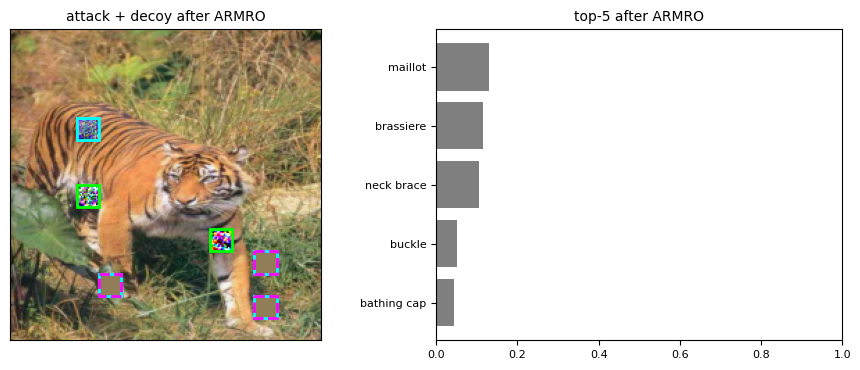

In [7]:
def_decoy = evaluate_armro_defense(model, x_decoy, decoy_out["attn_maps"], predict_fn, LAYERS, n_d=ARMRO_ND, tau=ARMRO_TAU, patch_size=PATCH_SIZE)
def_decoy_pred = int(def_decoy["after"]["pred"])
masked_decoy = def_decoy["selected_tokens"][0]

print("ARMRO masks:", masked_decoy)
print("  decoy tokens masked:   ", sorted(set(masked_decoy) & set(decoy_tokens)))
print("  attacked tokens masked:", sorted(set(masked_decoy) & set(attack_tokens)))
print(f"prediction after ARMRO: {name(def_decoy_pred)} | true label restored: {def_decoy_pred == label}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
show_image(axes[0], def_decoy["x_defended_01"], "attack + decoy after ARMRO")
draw_tokens(axes[0], attack_tokens, GRID_SIZE, PATCH_SIZE, color="lime")
draw_tokens(axes[0], decoy_tokens, GRID_SIZE, PATCH_SIZE, color="cyan")
draw_tokens(axes[0], masked_decoy, GRID_SIZE, PATCH_SIZE, color="magenta", linestyle="--")
show_topk(axes[1], def_decoy["after"]["probs"], class_names, highlight=label, title="top-5 after ARMRO")
plt.tight_layout()
plt.show()

## g. Summary

One row per input (clean, Patch-Fool, Patch-Fool + decoy). Columns: the input with attacked (green) and decoy (cyan) tokens, the attention received with the tokens ARMRO masks (magenta, dashed), and the top-5 predictions before and after ARMRO (green bar = true label). The figure is also saved to `assets/summary.png`.

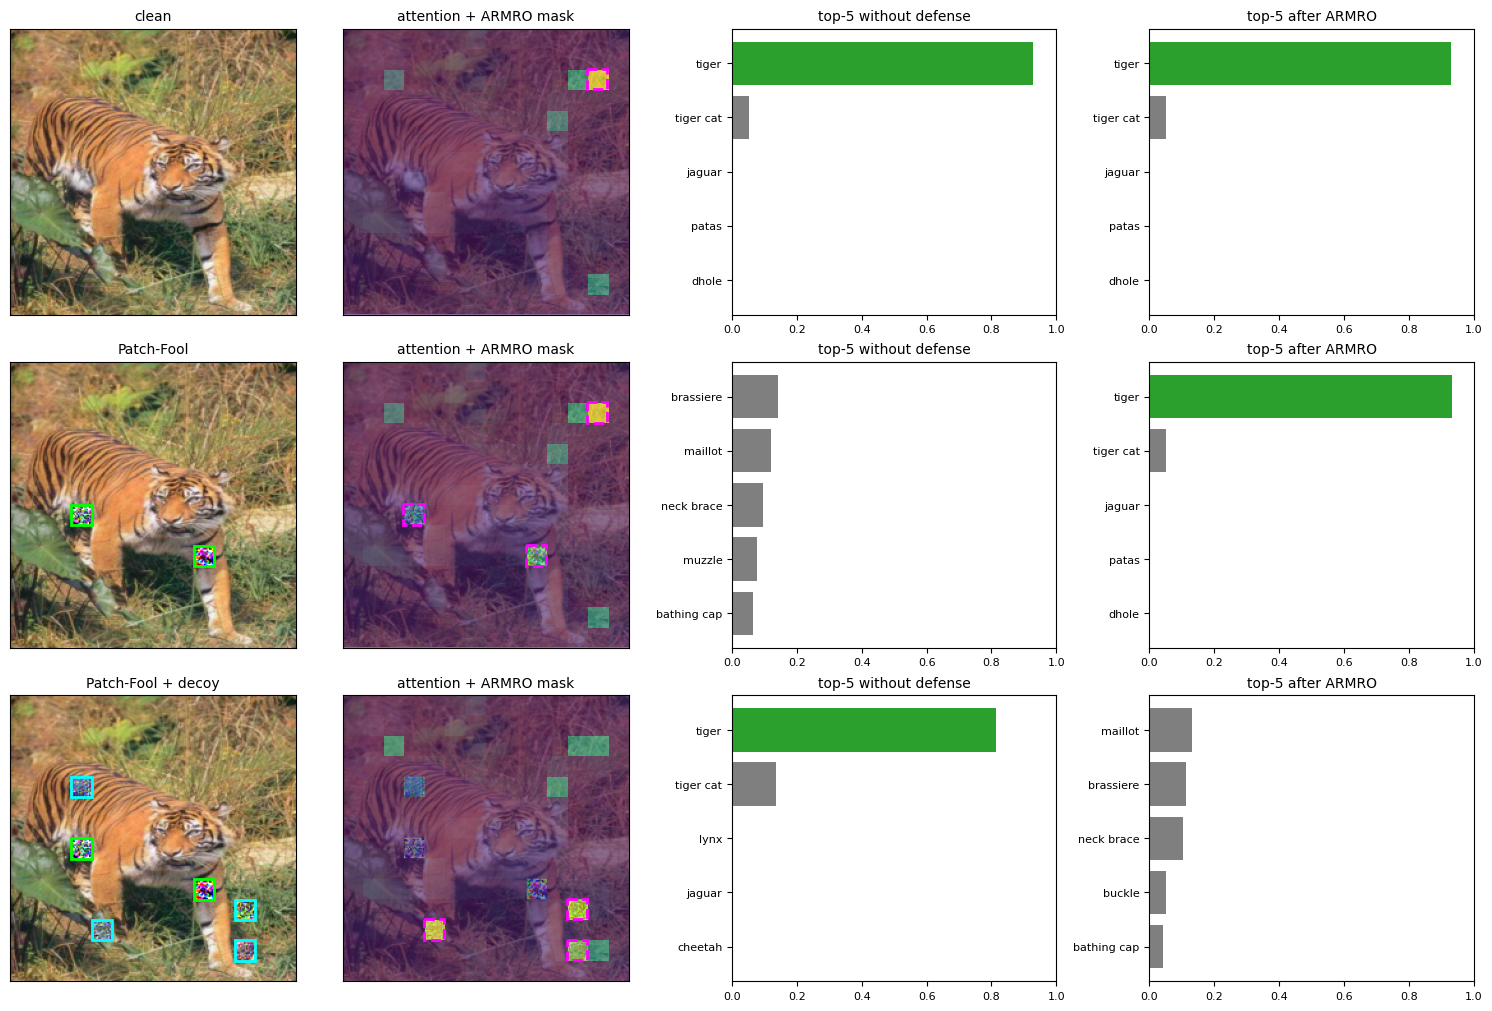

input               no defense                      after ARMRO                     
clean               tiger (292)                     tiger (292)                     
Patch-Fool          brassiere (459)                 tiger (292)                     
Patch-Fool + decoy  tiger (292)                     maillot (638)                   

attack succeeds:             True
ARMRO recovers the attack:   True
decoy defeats ARMRO:         True
total time: 46 s on cuda


In [8]:
def_clean = evaluate_armro_defense(model, x_clean, clean_out["attn_maps"], predict_fn, LAYERS, n_d=ARMRO_ND, tau=ARMRO_TAU, patch_size=PATCH_SIZE)

rows = [
    ("clean", x_clean, clean_out, def_clean, [], []),
    ("Patch-Fool", x_adv, adv_out, def_adv, attack_tokens, []),
    ("Patch-Fool + decoy", x_decoy, decoy_out, def_decoy, attack_tokens, decoy_tokens),
]

fig, axes = plt.subplots(3, 4, figsize=(15, 10), layout="constrained")
for i, (title, x, out, defense, atk, dec) in enumerate(rows):
    show_image(axes[i, 0], x, title)
    draw_tokens(axes[i, 0], atk, GRID_SIZE, PATCH_SIZE, color="lime")
    draw_tokens(axes[i, 0], dec, GRID_SIZE, PATCH_SIZE, color="cyan")
    show_attention(axes[i, 1], x, received_attention_map(out["attn_maps"], LAYERS), "attention + ARMRO mask")
    draw_tokens(axes[i, 1], defense["selected_tokens"][0], GRID_SIZE, PATCH_SIZE, color="magenta", linestyle="--")
    show_topk(axes[i, 2], out["probs"], class_names, highlight=label, title="top-5 without defense")
    show_topk(axes[i, 3], defense["after"]["probs"], class_names, highlight=label, title="top-5 after ARMRO")
fig.savefig(os.path.join(ROOT, "assets", "summary.png"), dpi=110, bbox_inches="tight")
plt.show()

print(f"{'input':<20}{'no defense':<32}{'after ARMRO':<32}")
for title, x, out, defense, atk, dec in rows:
    print(f"{title:<20}{name(int(out['pred'])):<32}{name(int(defense['after']['pred'])):<32}")

print()
print("attack succeeds:            ", adv_pred != label)
print("ARMRO recovers the attack:  ", def_adv_pred == label)
print("decoy defeats ARMRO:        ", def_decoy_pred != label)
print(f"total time: {time.time() - t_start:.0f} s on {DEVICE}")